In [2]:
!pip install --no-index --find-links /kaggle/input/datasets/hinlphmhng/uav-seg-offline-assets/offline_assets/packages segmentation-models-pytorch albumentations omegaconf torchmetrics

Looking in links: /kaggle/input/datasets/hinlphmhng/uav-seg-offline-assets/offline_assets/packages


In [3]:
import os
from pathlib import Path

# ============================================================
# CẤU HÌNH ĐƯỜNG DẪN — SUNNY + OVERCAST
# ============================================================
SUNNY_DIRS = [
    Path('/kaggle/input/datasets/leehien12/uav-forest-sunny-part1'),
    Path('/kaggle/input/datasets/khesng/uav-forest-sunny-next'),
    Path('/kaggle/input/datasets/leehien12/uav-forest-sunny'),
]
OVERCAST_DIRS = [
    Path('/kaggle/input/datasets/hinlphmhng/uav-forest-overcast-1'),
    Path('/kaggle/input/datasets/hinlphmhng/uav-forest-overcast-2'),
]

# ============================================================
# SPLIT THEO SEQUENCE
# Sunny:   seq1–seq9   (9 sequences)
# Overcast: seq10–seq18 (9 sequences, đặt tên tương tự)
#
# Train = 6 sunny + 6 overcast (tỷ lệ 2/3)
# Val   = 1 sunny + 1 overcast
# Test  = 2 sunny + 2 overcast
# ============================================================
SPLIT_CONFIG = {
    'train': ['seq1', 'seq3', 'seq4', 'seq5', 'seq8', 'seq9',   # 6 sunny
              'seq10', 'seq12', 'seq14', 'seq15', 'seq16', 'seq17'],  # 6 overcast
    'val':   ['seq2', 'seq13', 'seq18'],                                  # 1 sunny + 2 overcast
    'test':  ['seq6', 'seq7', 'seq11'],                 # 2 sunny + 1 overcast
}

def collect_pairs_from_dirs(base_dirs, split_config):
    """
    Duyệt qua danh sách thư mục, tìm cặp (image, mask) và
    phân loại vào train/val/test theo tên sequence.
    Trả về: dict với keys 'train', 'val', 'test'
    """
    data = {'train': [], 'val': [], 'test': []}
    found_sequences = {}

    all_dirs = base_dirs if isinstance(base_dirs, list) else [base_dirs]

    for base_path in all_dirs:
        if not Path(base_path).exists():
            print(f"  ⚠️  Không tìm thấy: {base_path}")
            continue

        for color_dir in Path(base_path).rglob('color'):
            if not color_dir.is_dir():
                continue

            seq_dir  = color_dir.parent
            seq_name = seq_dir.name

            # Tìm thư mục mask
            mask_dir = seq_dir / 'labels'
            if not mask_dir.exists():
                mask_dir = seq_dir / 'label'
            if not mask_dir.exists():
                continue

            # Xác định tập
            target_set = None
            for key, seq_list in split_config.items():
                if seq_name in seq_list:
                    target_set = key
                    break
            if not target_set:
                print(f"  [CẢNH BÁO] '{seq_name}' không trong SPLIT_CONFIG, bỏ qua.")
                continue

            # Ghép cặp image–mask
            n_added = 0
            for img_p in sorted(list(color_dir.glob('*.png')) + list(color_dir.glob('*.jpg'))):
                mask_p = (mask_dir / img_p.name).with_suffix('.png')
                if not mask_p.exists():
                    mask_p = (mask_dir / img_p.name).with_suffix('.jpg')
                if mask_p.exists():
                    data[target_set].append((str(img_p), str(mask_p)))
                    n_added += 1

            found_sequences[seq_name] = {'set': target_set, 'count': n_added,
                                          'source': Path(base_path).name}

    return data, found_sequences

# ============================================================
# CHẠY THU THẬP
# ============================================================
print("=" * 60)
print("  THU THẬP TOÀN BỘ DATA SUNNY + OVERCAST")
print("=" * 60)

all_dirs = SUNNY_DIRS + OVERCAST_DIRS
data, found_seqs = collect_pairs_from_dirs(all_dirs, SPLIT_CONFIG)

train_files = data['train']
val_files   = data['val']
test_files  = data['test']

# Kiểm tra sequences mong đợi
expected = set(SPLIT_CONFIG['train'] + SPLIT_CONFIG['val'] + SPLIT_CONFIG['test'])
missing  = expected - set(found_seqs.keys())
if missing:
    print(f"\n  ❌ THIẾU sequences: {sorted(missing)}")
    print("     → Kiểm tra lại tên thư mục trong dataset Kaggle.\n")
else:
    print("\n  ✅ Tìm thấy đủ tất cả sequences.")

# Báo cáo
print("\n  Sequences tìm thấy:")
for seq, info in sorted(found_seqs.items()):
    print(f"    {seq:8s} → {info['set']:6s} | {info['count']:5,} ảnh | [{info['source']}]")

total = len(train_files) + len(val_files) + len(test_files)
print(f"\n{'─'*60}")
print(f"  ✅ TRAIN : {len(train_files):6,} cặp (ảnh, mask)")
print(f"  ✅ VAL   : {len(val_files):6,} cặp")
print(f"  ✅ TEST  : {len(test_files):6,} cặp")
print(f"  📊 TỔNG  : {total:6,} cặp")
print(f"{'─'*60}")

if total == 0:
    raise ValueError("Không tìm thấy data! Kiểm tra lại đường dẫn.")

  THU THẬP TOÀN BỘ DATA SUNNY + OVERCAST

  ✅ Tìm thấy đủ tất cả sequences.

  Sequences tìm thấy:
    seq1     → train  | 1,468 ảnh | [uav-forest-sunny-part1]
    seq10    → train  | 1,522 ảnh | [uav-forest-overcast-1]
    seq11    → test   | 1,618 ảnh | [uav-forest-overcast-1]
    seq12    → train  | 1,556 ảnh | [uav-forest-overcast-1]
    seq13    → val    | 1,398 ảnh | [uav-forest-overcast-1]
    seq14    → train  | 1,398 ảnh | [uav-forest-overcast-2]
    seq15    → train  | 1,341 ảnh | [uav-forest-overcast-2]
    seq16    → train  | 1,489 ảnh | [uav-forest-overcast-2]
    seq17    → train  | 1,471 ảnh | [uav-forest-overcast-2]
    seq18    → val    | 1,398 ảnh | [uav-forest-overcast-2]
    seq2     → val    | 1,501 ảnh | [uav-forest-sunny-part1]
    seq3     → train  | 1,469 ảnh | [uav-forest-sunny-part1]
    seq4     → train  | 1,432 ảnh | [uav-forest-sunny-part1]
    seq5     → train  | 1,447 ảnh | [uav-forest-sunny-next]
    seq6     → test   | 1,437 ảnh | [uav-forest-sunny-nex

In [4]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

LABEL_COLORS = [
    (0, 255, 255),    # 0: Sky
    (0, 127, 0),      # 1: Deciduous_trees
    (19, 132, 69),    # 2: Coniferous_trees
    (0, 53, 65),      # 3: Fallen_trees
    (130, 76, 0),     # 4: Dirt_ground
    (152, 251, 152),  # 5: Ground_vegetation
    (151, 126, 171),  # 6: Rocks
    (250, 150, 0),    # 7: Building
    (115, 176, 195),  # 8: Fence
    (123, 123, 123),  # 9: Car
    (0, 0, 0),        # 10: Empty
]
CLASS_NAMES = [
    'Sky', 'Deciduous_trees', 'Coniferous_trees', 'Fallen_trees',
    'Dirt_ground', 'Ground_vegetation', 'Rocks', 'Building',
    'Fence', 'Car', 'Empty',
]
NUM_CLASSES = len(CLASS_NAMES)  # = 11
PALETTE = np.array(LABEL_COLORS, dtype=np.uint8)

RGB_TO_CLASS_LUT = np.full((256, 256, 256), NUM_CLASSES - 1, dtype=np.uint8)
for cid, color in enumerate(LABEL_COLORS):
    RGB_TO_CLASS_LUT[color[0], color[1], color[2]] = cid

def fast_rgb_to_mask(rgb_arr):
    return RGB_TO_CLASS_LUT[rgb_arr[..., 0], rgb_arr[..., 1], rgb_arr[..., 2]]

def class_id_to_rgb_fast(class_map):
    return PALETTE[class_map]

print(f"[OK] Label mapping: {NUM_CLASSES} classes (bao gồm Empty ở index 10)")

[OK] Label mapping: 11 classes (bao gồm Empty ở index 10)


In [5]:
import os
import random
import numpy as np
import torch

def seed_everything(seed=2025):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

SEED = 123
seed_everything(SEED)

MODEL_NAME      = 'upernet'
ENCODER         = 'mit_b4'
ENCODER_WEIGHTS = 'imagenet'
IMG_SIZE        = (768, 1280)   # ✅ Fix: giữ đúng tỷ lệ gốc 1280×768
BATCH_SIZE      = 4
EPOCHS          = 50
LR              = 1e-4
NUM_WORKERS     = 4
PATIENCE        = 10
SAVE_TOP_K      = 1
USE_AMP         = True

NUM_CLASSES     = 11

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"[INFO] Device: {DEVICE}")
if DEVICE == 'cuda':
    print(f"[INFO] GPU: {torch.cuda.get_device_name()}")
print(f"[INFO] IMG_SIZE (H, W): {IMG_SIZE} — đúng tỷ lệ gốc 1280×768")
print(f"[INFO] NUM_CLASSES: {NUM_CLASSES}")

[INFO] Device: cuda
[INFO] GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition
[INFO] IMG_SIZE (H, W): (768, 1280) — đúng tỷ lệ gốc 1280×768
[INFO] NUM_CLASSES: 11


In [6]:
import os
from pathlib import Path

IS_KAGGLE  = os.path.exists('/kaggle')
OUTPUT_DIR = Path('/kaggle/working/outputs') if IS_KAGGLE else Path('outputs')
CKPT_DIR   = OUTPUT_DIR / 'checkpoints'
CKPT_DIR.mkdir(parents=True, exist_ok=True)

def upload_to_drive(path):
    pass

In [7]:
import torch
import os

class CheckpointSaver:
    def __init__(self, dirpath, maximize=True):
        """
        top_k=1 cố định — chỉ giữ đúng 1 checkpoint tốt nhất.
        Early stopping được tích hợp qua thuộc tính no_improve.
        """
        self.dirpath      = dirpath
        self.maximize     = maximize
        self.best_score   = None
        self.best_path    = None   # đường dẫn file checkpoint tốt nhất hiện tại

    def save_if_best(self, state_dict, epoch, current_score):
        """
        Trả về True nếu current_score là best → đồng nghĩa no_improve reset về 0.
        Trả về False nếu không phải best → caller tăng no_improve lên 1.
        """
        is_better = (
            self.best_score is None or
            (self.maximize     and current_score > self.best_score) or
            (not self.maximize and current_score < self.best_score)
        )

        if is_better:
            # Xóa checkpoint cũ trước khi lưu mới
            if self.best_path and os.path.exists(self.best_path):
                # FIX BẢO VỆ: Không xóa file nếu nó nằm trong thư mục /kaggle/input
                if '/kaggle/input' not in self.best_path:
                    try:
                        os.remove(self.best_path)
                        print(f'  🗑️  Đã xóa checkpoint cũ: {os.path.basename(self.best_path)}')
                    except Exception as e:
                        print(f'  ⚠️  Không thể xóa checkpoint cũ. Lỗi: {e}')
                else:
                    print(f'  🛡️  Bỏ qua xóa checkpoint cũ vì thuộc thư mục Read-only (Input)')

            # Tạo file mới và lưu
            filename        = f"epoch_{epoch:03d}_miou_{current_score:.4f}.pth"
            filepath        = os.path.join(self.dirpath, filename)
            torch.save(state_dict, filepath)
            
            # Hàm upload lên Drive của bạn
            upload_to_drive(filepath)

            self.best_score = current_score
            self.best_path  = filepath
            print(f'  ✅ [BEST] mIoU: {current_score:.4f} → {filename}')
            return True

        return False

    def set_best(self, score, path=None):
        """
        Dùng khi resume: khởi tạo lại best_score từ checkpoint đã load,
        không cần file thực sự tồn tại (chỉ dùng score để so sánh).
        """
        self.best_score = score
        self.best_path  = path
        print(f'  [Saver] Best score khởi tạo từ checkpoint: {score:.4f}')

In [8]:
import torch
import random
import numpy as np
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import albumentations as A
from albumentations.pytorch import ToTensorV2

class ForestDataset(Dataset):
    def __init__(self, file_list, transform=None):
        self.file_list = file_list
        self.transform = transform

    def __len__(self):
        return len(self.file_list)

    def __getitem__(self, idx):
        img_path, mask_path = self.file_list[idx]
        img      = np.array(Image.open(img_path).convert('RGB'))
        mask_rgb = np.array(Image.open(mask_path).convert('RGB'))
        mask     = fast_rgb_to_mask(mask_rgb)
        if self.transform:
            aug       = self.transform(image=img, mask=mask)
            img, mask = aug['image'], aug['mask']
        return img, mask.long()


H, W = IMG_SIZE  # (768, 1280)
EMPTY_CLASS = NUM_CLASSES - 1  # = 10

train_tf = A.Compose([
    A.Resize(height=H, width=W),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Affine(
        scale=(0.9, 1.1),
        rotate=(-15, 15),
        translate_percent={"x": (-0.0625, 0.0625), "y": (-0.0625, 0.0625)},
        p=0.3,
        border_mode=0,
        fill=0,
        fill_mask=EMPTY_CLASS,
    ),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.3),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

val_tf = A.Compose([
    A.Resize(height=H, width=W),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

train_ds = ForestDataset(train_files, train_tf)
val_ds   = ForestDataset(val_files,   val_tf)

def worker_init_fn(worker_id):
    np.random.seed(SEED + worker_id)
    random.seed(SEED + worker_id)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
    worker_init_fn=worker_init_fn,
    generator=torch.Generator().manual_seed(SEED),
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
)

print(f"[OK] Resize cứng (H×W): {H}×{W}")
print(f"[OK] Train: {len(train_loader)} batches | Val: {len(val_loader)} batches")

[OK] Resize cứng (H×W): 768×1280
[OK] Train: 4363 batches | Val: 1075 batches


/usr/local/lib/python3.13/dist-packages/albumentations/check_version.py:147: UserWarning: Error fetching version info <urlopen error [Errno -3] Temporary failure in name resolution>
  data = fetch_version_info()


In [9]:
import shutil, glob
import torch.nn as nn
import segmentation_models_pytorch as smp

print("=== CHUẨN BỊ TRỌNG SỐ OFFLINE ===")
CACHE_DIR = '/root/.cache/torch/hub/checkpoints/'
os.makedirs(CACHE_DIR, exist_ok=True)

# ✅ Sửa path Kaggle dataset
WEIGHT_DIR = '/kaggle/input/datasets/phmnguynkimquyn/smp-mit-b4-weights'
pth_files  = glob.glob(os.path.join(WEIGHT_DIR, '*.pth'))
if pth_files:
    cache_file = os.path.join(CACHE_DIR, 'mit_b4.pth')
    if not os.path.exists(cache_file):
        shutil.copy(pth_files[0], cache_file)
        print(f"[OK] Đã copy: {os.path.basename(pth_files[0])} -> Cache")
    else:
        print("[OK] Trọng số đã có trong cache.")
else:
    print("[CẢNH BÁO] Không tìm thấy .pth offline, sẽ tải từ Internet.")

MODELS = {
    'unet':          lambda: smp.Unet(encoder_name=ENCODER, encoder_weights='imagenet', in_channels=3, classes=NUM_CLASSES),
    'unetpp':        lambda: smp.UnetPlusPlus(encoder_name=ENCODER, encoder_weights='imagenet', in_channels=3, classes=NUM_CLASSES),
    'deeplabv3plus': lambda: smp.DeepLabV3Plus(encoder_name=ENCODER, encoder_weights='imagenet', in_channels=3, classes=NUM_CLASSES),
    'segformer':     lambda: smp.Segformer(encoder_name=ENCODER, encoder_weights='imagenet', in_channels=3, classes=NUM_CLASSES),
    'manet':         lambda: smp.MAnet(encoder_name=ENCODER, encoder_weights='imagenet', in_channels=3, classes=NUM_CLASSES),
    'upernet':       lambda: smp.UPerNet(encoder_name=ENCODER, encoder_weights='imagenet', in_channels=3, classes=NUM_CLASSES),
}

if MODEL_NAME not in MODELS:
    raise ValueError(f"MODEL_NAME '{MODEL_NAME}' không hợp lệ. Chọn trong: {list(MODELS.keys())}")

model = MODELS[MODEL_NAME]().to(DEVICE)
print(f'🚀 MODEL: {MODEL_NAME} | Encoder: {ENCODER} | Classes: {NUM_CLASSES}')
print(f'📊 Params: {sum(p.numel() for p in model.parameters()):,}')

=== CHUẨN BỊ TRỌNG SỐ OFFLINE ===
[OK] Đã copy: mit_b4.pth -> Cache


'[Errno -3] Temporary failure in name resolution' thrown while requesting HEAD https://huggingface.co/smp-hub/mit_b4.imagenet/resolve/3a3454e900a4b4f11dd60eeb59101a9a1a36b017/config.json
Retrying in 1s [Retry 1/5].
'[Errno -3] Temporary failure in name resolution' thrown while requesting HEAD https://huggingface.co/smp-hub/mit_b4.imagenet/resolve/3a3454e900a4b4f11dd60eeb59101a9a1a36b017/config.json
Retrying in 2s [Retry 2/5].
'[Errno -3] Temporary failure in name resolution' thrown while requesting HEAD https://huggingface.co/smp-hub/mit_b4.imagenet/resolve/3a3454e900a4b4f11dd60eeb59101a9a1a36b017/config.json
Retrying in 4s [Retry 3/5].
'[Errno -3] Temporary failure in name resolution' thrown while requesting HEAD https://huggingface.co/smp-hub/mit_b4.imagenet/resolve/3a3454e900a4b4f11dd60eeb59101a9a1a36b017/config.json
Retrying in 8s [Retry 4/5].
'[Errno -3] Temporary failure in name resolution' thrown while requesting HEAD https://huggingface.co/smp-hub/mit_b4.imagenet/resolve/3a3454

🚀 MODEL: upernet | Encoder: mit_b4 | Classes: 11
📊 Params: 69,176,779


In [10]:
from tqdm import tqdm

def compute_class_weights(file_list, num_classes, c=1.02):
    """
    Công thức từ bài báo gốc: w = 1 / ln(c + p_class)
    p_class = tỷ lệ pixel của class đó trong toàn bộ tập train
    """
    counts = np.zeros(num_classes, dtype=np.int64)
    for _, mask_path in tqdm(file_list, desc='Computing class weights'):
        mask_rgb = np.array(Image.open(mask_path).convert('RGB'))
        mask = fast_rgb_to_mask(mask_rgb)
        for cid in range(num_classes):
            counts[cid] += (mask == cid).sum()
    total = counts.sum()
    freq  = counts / total
    w     = 1.0 / np.log(c + freq)
    w     = w / w.sum() * num_classes  # normalize
    print("\n📊 Class weights:")
    for i, (name, wi, fi) in enumerate(zip(CLASS_NAMES, w, freq)):
        print(f"  {name:<22} freq={fi*100:6.3f}%  weight={wi:.4f}")
    return torch.tensor(w, dtype=torch.float32).to(DEVICE)

class_weights = compute_class_weights(train_files, NUM_CLASSES)

Computing class weights: 100%|██████████| 17454/17454 [07:03<00:00, 41.23it/s]


📊 Class weights:
  Sky                    freq=15.208%  weight=0.2260
  Deciduous_trees        freq=16.362%  weight=0.2128
  Coniferous_trees       freq=28.327%  weight=0.1355
  Fallen_trees           freq= 0.570%  weight=1.4142
  Dirt_ground            freq= 1.994%  weight=0.9162
  Ground_vegetation      freq=35.408%  weight=0.1129
  Rocks                  freq= 1.882%  weight=0.9421
  Building               freq= 0.191%  weight=1.6558
  Fence                  freq= 0.013%  weight=1.8006
  Car                    freq= 0.045%  weight=1.7720
  Empty                  freq= 0.000%  weight=1.8119


In [11]:
class CEFocalLoss(nn.Module):
    def __init__(self, class_weights=None):
        super().__init__()

        self.ce = nn.CrossEntropyLoss(
            weight=class_weights,
            ignore_index=NUM_CLASSES - 1
        )

        self.focal = smp.losses.FocalLoss(
            mode=smp.losses.MULTICLASS_MODE,
            gamma=2.0
        )

    def forward(self, logits, targets):
        l_ce = self.ce(logits, targets)
        l_focal = self.focal(logits, targets)

        loss = l_ce + l_focal

        return loss, {
            'focal': l_focal.item(),
            'dice': 0.0,
            'ce': l_ce.item(),
            'w_focal': 1.0,
            'w_dice': 0.0,
            'w_ce': 1.0,
        }

    def get_weights(self):
        return {
            'w_focal': 1.0,
            'w_dice': 0.0,
            'w_ce': 1.0,
        }


criterion = CEFocalLoss(
    class_weights=class_weights
).to(DEVICE)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS,
    eta_min=1e-6
)

scaler = torch.amp.GradScaler(
    'cuda',
    enabled=USE_AMP
)

print("✅ CEFocalLoss + Optimizer + Scheduler khởi tạo thành công!")
print(f"   Initial weights: {criterion.get_weights()}")

✅ CEFocalLoss + Optimizer + Scheduler khởi tạo thành công!
   Initial weights: {'w_focal': 1.0, 'w_dice': 0.0, 'w_ce': 1.0}


In [12]:
def get_miou(cm, n_ignore_last=1):
    """
    Tính mIoU từ confusion matrix.
    n_ignore_last=1  → bỏ class Empty (index 10) khỏi mIoU  ← LUÔN DÙNG GIÁ TRỊ NÀY
    n_ignore_last=0  → tính tất cả class (KHÔNG dùng cho eval chính thức)
    """
    inter = np.diag(cm)
    union = cm.sum(1) + cm.sum(0) - inter
    iou   = np.where(union > 0, inter / union, 0.0)

    valid_iou   = iou[:-n_ignore_last]   if n_ignore_last > 0 else iou
    valid_union = union[:-n_ignore_last] if n_ignore_last > 0 else union
    miou = valid_iou[valid_union > 0].mean() if any(valid_union > 0) else 0.0
    return miou, iou

print("[OK] get_miou định nghĩa với n_ignore_last=1 (bỏ class Empty khi eval)")

[OK] get_miou định nghĩa với n_ignore_last=1 (bỏ class Empty khi eval)


In [13]:
# Thay đổi so với code cũ:
# 1. cm khởi tạo với NUM_CLASSES=11 (nhất quán)
# 2. get_miou gọi với n_ignore_last=1 (mặc định)

import time, gc, csv

best_val_miou = -float('inf')
no_improve    = 0
saver = CheckpointSaver(dirpath=CKPT_DIR, maximize=True)

LOG_FILE = OUTPUT_DIR / 'training_log.csv'
with open(LOG_FILE, 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow([
        'epoch', 'train_loss', 'val_loss', 'miou',
        'w_focal', 'w_dice', 'w_ce',
        'l_focal', 'l_dice', 'l_ce',
        *CLASS_NAMES[:-1]   # 10 class, bỏ Empty
    ])

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()

    # ── TRAIN ──────────────────────────────────────────────
    model.train(); criterion.train()
    train_loss = 0.0; n_train = 0
    loss_components_sum = {'focal': 0, 'dice': 0, 'ce': 0,
                           'w_focal': 0, 'w_dice': 0, 'w_ce': 0}

    pbar_train = tqdm(train_loader, desc=f'E{epoch} [TRAIN]')
    for imgs, masks in pbar_train:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        optimizer.zero_grad()
        with torch.amp.autocast('cuda', enabled=USE_AMP):
            out              = model(imgs)
            loss, components = criterion(out, masks)
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update()
        train_loss += loss.item(); n_train += 1
        for k in loss_components_sum:
            loss_components_sum[k] += components[k]
        pbar_train.set_postfix({
            'loss': f'{loss.item():.4f}',
            'wF': f'{components["w_focal"]:.2f}',
            'wD': f'{components["w_dice"]:.2f}',
            'wCE': f'{components["w_ce"]:.2f}',
        })

    # ── VAL ────────────────────────────────────────────────
    model.eval(); criterion.eval()
    val_loss = 0.0; n_val = 0
    # ✅ Fix: cm luôn dùng NUM_CLASSES=11
    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)

    with torch.no_grad():
        for imgs, masks in tqdm(val_loader, desc=f'E{epoch} [VAL]'):
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            with torch.amp.autocast('cuda', enabled=USE_AMP):
                out       = model(imgs)
                loss, _   = criterion(out, masks)
            val_loss += loss.item(); n_val += 1
            preds = out.argmax(1).detach().cpu().numpy().flatten()
            t     = masks.detach().cpu().numpy().flatten()
            valid = (t >= 0) & (t < NUM_CLASSES)
            cm   += np.bincount(
                t[valid] * NUM_CLASSES + preds[valid],
                minlength=NUM_CLASSES ** 2
            ).reshape(NUM_CLASSES, NUM_CLASSES)

    # ── METRICS ────────────────────────────────────────────
    avg_train = train_loss / n_train
    avg_val   = val_loss   / n_val
    # ✅ Fix: n_ignore_last=1 → bỏ Empty khỏi mIoU
    miou, class_ious = get_miou(cm, n_ignore_last=1)
    avg_components   = {k: v / n_train for k, v in loss_components_sum.items()}
    scheduler.step()

    print(f'\n▶ Epoch {epoch:03d} | Train: {avg_train:.4f} | Val: {avg_val:.4f} | '
          f'mIoU: {miou:.4f} | {time.time()-t0:.0f}s')
    print(f'   Adaptive weights → Focal: {avg_components["w_focal"]:.3f} | '
          f'Dice: {avg_components["w_dice"]:.3f} | CE: {avg_components["w_ce"]:.3f}')

    with open(LOG_FILE, 'a', newline='') as f:
        writer = csv.writer(f)
        writer.writerow([
            epoch, avg_train, avg_val, miou,
            avg_components['w_focal'], avg_components['w_dice'], avg_components['w_ce'],
            avg_components['focal'],   avg_components['dice'],   avg_components['ce'],
            *[f'{class_ious[i]:.4f}' for i in range(NUM_CLASSES - 1)]
        ])

    checkpoint_dict = {
        'epoch':                epoch,
        'model_state_dict':     model.state_dict(),
        'criterion_state_dict': criterion.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'miou':                 miou,
        'loss_weights':         criterion.get_weights(),
        'scheduler_state_dict': scheduler.state_dict(),
        'scaler_state_dict':    scaler.state_dict(),
        'random_states': {
            'python': random.getstate(),
            'numpy':  np.random.get_state(),
            'torch':  torch.get_rng_state(),
            'cuda':   torch.cuda.get_rng_state_all(),
        },
    }
    is_best = saver.save_if_best(state_dict=checkpoint_dict,
                                  epoch=epoch, current_score=miou)
    if is_best:
        best_val_miou = miou; no_improve = 0
        print(f"  ⭐ New best mIoU={miou:.4f}! Class-wise IoU:")
        for i, name in enumerate(CLASS_NAMES[:-1]):
            print(f"    - {name:<22}: {class_ious[i]:.4f}")
    else:
        no_improve += 1

    del cm; gc.collect(); torch.cuda.empty_cache()

    if no_improve >= PATIENCE:
        print(f'🛑 Early Stopping at Epoch {epoch}')
        break

print(f'\n✅ Training done! Best val mIoU: {best_val_miou:.4f}')
print(f'   Final adaptive weights: {criterion.get_weights()}')

E1 [VAL]: 100%|██████████| 1075/1075 [02:22<00:00,  7.55it/s]



▶ Epoch 001 | Train: 0.5908 | Val: 0.4060 | mIoU: 0.7042 | 1504s
   Adaptive weights → Focal: 1.000 | Dice: 0.000 | CE: 1.000
  ✅ [BEST] mIoU: 0.7042 → epoch_001_miou_0.7042.pth
  ⭐ New best mIoU=0.7042! Class-wise IoU:
    - Sky                   : 0.9773
    - Deciduous_trees       : 0.7001
    - Coniferous_trees      : 0.7964
    - Fallen_trees          : 0.4378
    - Dirt_ground           : 0.8166
    - Ground_vegetation     : 0.8192
    - Rocks                 : 0.7441
    - Building              : 0.7901
    - Fence                 : 0.3388
    - Car                   : 0.6212


E2 [VAL]: 100%|██████████| 1075/1075 [02:18<00:00,  7.76it/s]



▶ Epoch 002 | Train: 0.4221 | Val: 0.3833 | mIoU: 0.7186 | 1494s
   Adaptive weights → Focal: 1.000 | Dice: 0.000 | CE: 1.000
  🗑️  Đã xóa checkpoint cũ: epoch_001_miou_0.7042.pth
  ✅ [BEST] mIoU: 0.7186 → epoch_002_miou_0.7186.pth
  ⭐ New best mIoU=0.7186! Class-wise IoU:
    - Sky                   : 0.9781
    - Deciduous_trees       : 0.7070
    - Coniferous_trees      : 0.8027
    - Fallen_trees          : 0.4407
    - Dirt_ground           : 0.8244
    - Ground_vegetation     : 0.8255
    - Rocks                 : 0.7565
    - Building              : 0.7935
    - Fence                 : 0.4287
    - Car                   : 0.6285


E3 [VAL]: 100%|██████████| 1075/1075 [02:18<00:00,  7.75it/s]



▶ Epoch 003 | Train: 0.3956 | Val: 0.3917 | mIoU: 0.7019 | 1492s
   Adaptive weights → Focal: 1.000 | Dice: 0.000 | CE: 1.000


... (42 outputs left out)

E25 [VAL]: 100%|██████████| 1075/1075 [02:15<00:00,  7.92it/s]
/tmp/ipykernel_91/3649730921.py:9: RuntimeWarning: invalid value encountered in divide
  iou   = np.where(union > 0, inter / union, 0.0)



▶ Epoch 025 | Train: nan | Val: nan | mIoU: 0.0158 | 1493s
   Adaptive weights → Focal: 1.000 | Dice: 0.000 | CE: 1.000


E26 [TRAIN]:  73%|███████▎  | 3192/4363 [16:07<05:55,  3.30it/s, loss=nan, wF=1.00, wD=0.00, wCE=1.00]


KeyboardInterrupt: 

In [15]:
import shutil
from IPython.display import FileLink

checkpoint_folder = '/kaggle/working/outputs/checkpoints'
output_zip_name   = '/kaggle/working/my_forest_checkpoints'

if os.path.exists(checkpoint_folder):
    shutil.make_archive(output_zip_name, 'zip', checkpoint_folder)
    print(f"✅ Archived: {output_zip_name}.zip")
    display(FileLink('my_forest_checkpoints.zip'))
else:
    print(f"❌ Folder not found: {checkpoint_folder}")

✅ Archived: /kaggle/working/my_forest_checkpoints.zip


/kaggle/working/my_forest_checkpoints.zip

In [17]:
# ============================================================
# CELL TEST: ĐÁNH GIÁ CHUẨN XÁC Ở ĐỘ CHÍNH XÁC FP32
# ============================================================
import os
import torch
import numpy as np
from torch.utils.data import DataLoader
from tqdm import tqdm

# Load best checkpoint
BEST_CKPT = '/kaggle/working/outputs/checkpoints/epoch_024_miou_0.7822.pth'

if os.path.exists(BEST_CKPT):
    ckpt = torch.load(BEST_CKPT, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt['model_state_dict'])
    print(f"✅ Loaded checkpoint | mIoU kỷ lục: {ckpt['miou']:.4f}")
else:
    print("⚠️ Dùng model hiện tại trong RAM.")

test_ds     = ForestDataset(test_files, val_tf)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)

model.eval()
NUM_CLASSES = 11 

cm_test = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)

with torch.no_grad():
    for imgs, masks in tqdm(test_loader, desc='Testing (FP32)'):
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        
        # ✅ CHUYỂN SANG FP32 (ĐỒNG BỘ VỚI TẬP VAL): Triệt tiêu hoàn toàn tràn số FP16
        with torch.amp.autocast('cuda', enabled=False):
            out = model(imgs.float())
        
        preds   = out.argmax(1).detach().cpu().numpy().flatten()
        targets = masks.detach().cpu().numpy().flatten()
        
        # Lọc các giá trị hợp lệ
        valid = (targets >= 0) & (targets < NUM_CLASSES) & (preds >= 0) & (preds < NUM_CLASSES)
        
        bin_counts = np.bincount(
            targets[valid] * NUM_CLASSES + preds[valid],
            minlength=NUM_CLASSES ** 2
        )
        cm_test += bin_counts.reshape(NUM_CLASSES, NUM_CLASSES)

# ✅ Tính toán mIoU (bỏ class cuối cùng - Empty)
miou_test, ious_test = get_miou(cm_test, n_ignore_last=1)

print("\n" + "="*55)
print("  📊 KẾT QUẢ TEST SET CHUẨN XÁC (seq6, seq7, seq11)")
print("="*55)
print(f"  {'Class':<22} {'IoU':>8}")
print("─"*55)
for i, name in enumerate(CLASS_NAMES[:-1]):
    status = f"{ious_test[i]:.4f}" if cm_test.sum(1)[i] > 0 else "  N/A"
    print(f"  {name:<22} {status:>8}")
print("─"*55)
print(f"  {'mIoU (10 classes)':<22} {miou_test:>8.4f}")
print("="*55)

✅ Loaded checkpoint | mIoU kỷ lục: 0.7822


Testing (FP32): 100%|██████████| 1123/1123 [03:26<00:00,  5.45it/s]


  📊 KẾT QUẢ TEST SET CHUẨN XÁC (seq6, seq7, seq11)
  Class                       IoU
───────────────────────────────────────────────────────
  Sky                      0.9916
  Deciduous_trees          0.7439
  Coniferous_trees         0.8228
  Fallen_trees             0.5823
  Dirt_ground              0.8658
  Ground_vegetation        0.8612
  Rocks                    0.8226
  Building                 0.8812
  Fence                    0.5830
  Car                      0.7940
───────────────────────────────────────────────────────
  mIoU (10 classes)        0.7948


Class Name         | Dice / F1  | Boundary IoU
---------------------------------------------
Sky                | 0.9969     | 0.8131
Deciduous trees    | 0.8156     | 0.1484
Coniferous trees   | 0.8765     | 0.1811
Fallen trees       | 0.5741     | 0.2403
Dirt ground        | 0.8723     | 0.5003
Ground vegetation  | 0.8748     | 0.1919
Rocks              | 0.8923     | 0.4817
Building           | 0.9056     | 0.7036
Fence              | 0.9383     | 0.8655
Car                | 0.8949     | 0.7560
---------------------------------------------
AVERAGE (All)      | 0.8641     | 0.4882
AVERAGE (No BG)    | 0.8494     | 0.4521


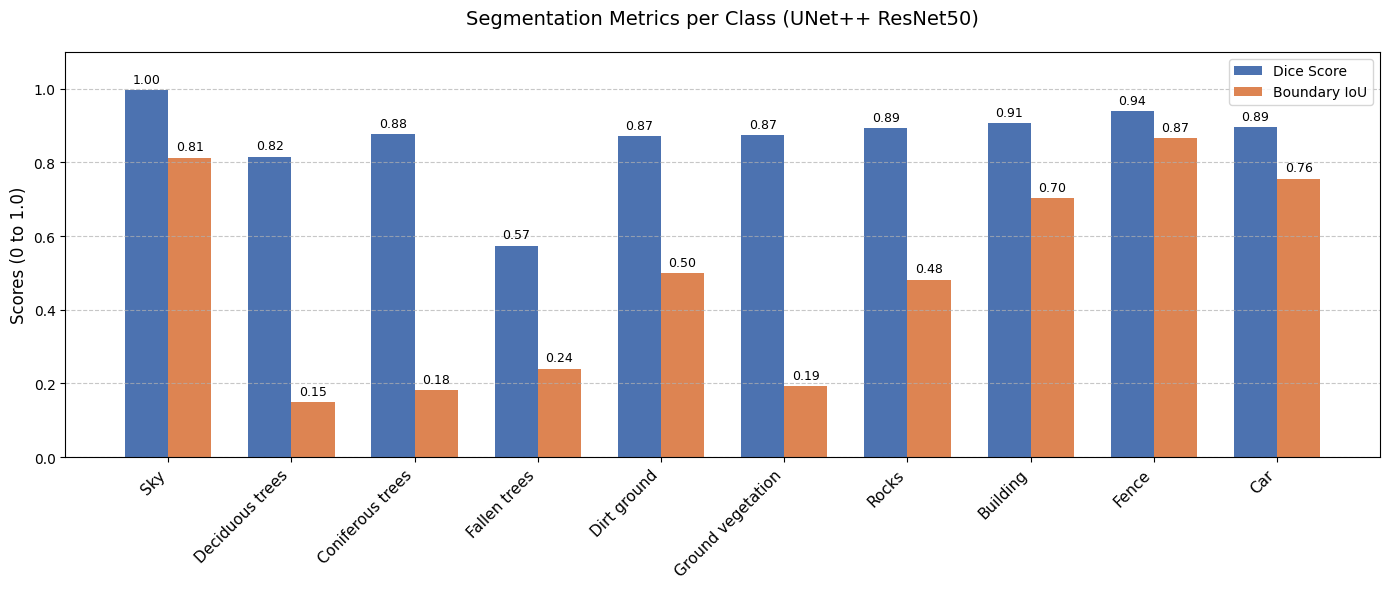

In [18]:
import os
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

# ==========================================
# 1. HÀM CHUYỂN ĐỔI ONE-HOT
# ==========================================
def to_one_hot(mask, num_classes):
    if mask.dim() == 4 and mask.shape[1] == 1:
        mask = mask.squeeze(1)
    
    # Bảo vệ bổ sung: Clamp một lần nữa trước khi vào F.one_hot cho chắc cú
    safe_mask = torch.clamp(mask.long(), min=0, max=num_classes-1)
    one_hot = F.one_hot(safe_mask, num_classes=num_classes)
    return one_hot.permute(0, 3, 1, 2).float()

# ==========================================
# 2. HÀM TÍNH METRICS (Tuyệt tác do bạn tối ưu)
# ==========================================
def calculate_metrics_multiclass_per_class(pred_logits, target, num_classes, smooth=1e-6):
    # Squeeze nếu (B,1,H,W)
    if target.dim() == 4 and target.shape[1] == 1:
        target = target.squeeze(1)

    pred_mask = torch.argmax(pred_logits, dim=1)  # (B, H, W)

    # Pixel nào có nhãn >= num_classes (vd: EMPTY_CLASS=10) → loại khỏi metric
    valid_mask = (target >= 0) & (target < num_classes)  # (B, H, W)

    # Clamp để tránh index out of bounds khi gọi one_hot
    # Pixel không hợp lệ sẽ bị zero-out bởi valid_mask sau đó
    target_clean = target.clamp(0, num_classes - 1)

    pred_one_hot   = to_one_hot(pred_mask,    num_classes)  # (B, C, H, W)
    target_one_hot = to_one_hot(target_clean, num_classes)  # (B, C, H, W)

    # Zero-out pixel không hợp lệ (EMPTY_CLASS=10 đã bị loại)
    valid_mask_4d  = valid_mask.unsqueeze(1).float()        # (B, 1, H, W)
    pred_one_hot   = pred_one_hot   * valid_mask_4d
    target_one_hot = target_one_hot * valid_mask_4d

    # --- DICE SCORE ---
    inter = (pred_one_hot * target_one_hot).sum(dim=(2, 3))
    union = pred_one_hot.sum(dim=(2, 3)) + target_one_hot.sum(dim=(2, 3))
    dice_per_class = (2. * inter + smooth) / (union + smooth)  # (B, C)

    # --- BOUNDARY IOU ---
    kernel_size = 3
    pad    = kernel_size // 2
    kernel = torch.ones(
        (num_classes, 1, kernel_size, kernel_size),
        device=pred_logits.device
    )

    eroded_pred   = F.conv2d(pred_one_hot,   kernel, padding=pad, groups=num_classes)
    eroded_pred   = (eroded_pred == kernel_size * kernel_size).float()
    pred_boundary = pred_one_hot - eroded_pred

    eroded_target   = F.conv2d(target_one_hot, kernel, padding=pad, groups=num_classes)
    eroded_target   = (eroded_target == kernel_size * kernel_size).float()
    target_boundary = target_one_hot - eroded_target

    b_inter = (pred_boundary * target_boundary).sum(dim=(2, 3))
    b_union = (
        pred_boundary.sum(dim=(2, 3))
        + target_boundary.sum(dim=(2, 3))
        - b_inter
    )
    biou_per_class = (b_inter + smooth) / (b_union + smooth)  # (B, C)

    return dice_per_class.mean(dim=0), biou_per_class.mean(dim=0)  # (C,)

# ==========================================
# 3. HÀM ĐÁNH GIÁ VÀ VẼ BIỂU ĐỒ (Phần bị thiếu)
# ==========================================
def evaluate_model_and_plot(model, dataloader, num_classes, class_names=None, device="cuda"):
    model.eval()
    
    total_dice_classes = torch.zeros(num_classes, device=device)
    total_biou_classes = torch.zeros(num_classes, device=device)
    n_batches = 0
    
    with torch.no_grad():
        for images, masks in dataloader:
            images = images.to(device)
            masks = masks.to(device)
            
            # Autocast giúp GPU chạy mượt và không bị tràn RAM
            with torch.amp.autocast('cuda'): 
                preds = model(images)
            
            batch_dice_classes, batch_biou_classes = calculate_metrics_multiclass_per_class(preds, masks, num_classes)
            
            total_dice_classes += batch_dice_classes
            total_biou_classes += batch_biou_classes
            n_batches += 1
            
    final_dice_classes = (total_dice_classes / n_batches).cpu().numpy()
    final_biou_classes = (total_biou_classes / n_batches).cpu().numpy()
    
    if class_names is None:
        class_names = [f"Class {i}" for i in range(num_classes)]
        
    print(f"{'Class Name':<18} | {'Dice / F1':<10} | {'Boundary IoU':<10}")
    print("-" * 45)
    for i in range(num_classes):
        print(f"{class_names[i]:<18} | {final_dice_classes[i]:.4f}     | {final_biou_classes[i]:.4f}")
    print("-" * 45)
    print(f"{'AVERAGE (All)':<18} | {final_dice_classes.mean():.4f}     | {final_biou_classes.mean():.4f}")
    print(f"{'AVERAGE (No BG)':<18} | {final_dice_classes[1:].mean():.4f}     | {final_biou_classes[1:].mean():.4f}")

    # --- VẼ BIỂU ĐỒ ---
    x = np.arange(num_classes)
    width = 0.35

    fig, ax = plt.subplots(figsize=(14, 6))
    rects1 = ax.bar(x - width/2, final_dice_classes, width, label='Dice Score', color='#4C72B0')
    rects2 = ax.bar(x + width/2, final_biou_classes, width, label='Boundary IoU', color='#DD8452')

    ax.set_ylabel('Scores (0 to 1.0)', fontsize=12)
    ax.set_title('Segmentation Metrics per Class (UNet++ ResNet50)', fontsize=14, pad=20)
    ax.set_xticks(x)
    ax.set_xticklabels(class_names, rotation=45, ha='right', fontsize=11)
    ax.legend(loc='upper right')
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.set_ylim(0, 1.1)

    for rect in rects1 + rects2:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), 
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

    plt.tight_layout()
    plt.savefig('metrics_per_class.png', dpi=300, bbox_inches='tight') 
    plt.show()

# ==========================================
# 4. THỰC THI CHÍNH CỦA BẠN
# ==========================================
my_class_names = [
    "Sky", "Deciduous trees", "Coniferous trees", "Fallen trees",
    "Dirt ground", "Ground vegetation", "Rocks", "Building",
    "Fence", "Car"
]
NUM_CLASSES = 10

device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

evaluate_model_and_plot(
    model=model,
    dataloader=test_loader,
    num_classes=NUM_CLASSES,
    class_names=my_class_names,
    device=device
)

In [19]:
# =====================================================
# TÍNH ĐẦY ĐỦ METRICS TỪ CONFUSION MATRIX ĐÃ CÓ
# Chạy SAU khi đã có cm_test, không cần inference lại
# =====================================================

def compute_all_metrics(cm, class_names, n_ignore_last=1):
    n = len(class_names)
    valid = slice(0, n - n_ignore_last)  # bỏ class Empty
    
    inter = np.diag(cm)
    sum_row = cm.sum(1)  # GT per class
    sum_col = cm.sum(0)  # Pred per class
    union   = sum_row + sum_col - inter
    total_pixels = cm.sum()

    # --- Per-class IoU ---
    iou = np.where(union > 0, inter / union, 0.0)
    valid_mask = union[valid] > 0
    miou = iou[valid][valid_mask].mean()

    # --- Frequency Weighted IoU (FWIoU) ---
    freq = sum_row[valid] / total_pixels  # tần suất từng class
    fwiou = (freq * iou[valid]).sum()

    # --- Pixel Accuracy ---
    pixel_acc = inter.sum() / total_pixels

    # --- Mean Pixel Accuracy (per-class accuracy rồi average) ---
    class_acc = np.where(sum_row > 0, inter / sum_row, 0.0)
    mean_pixel_acc = class_acc[valid][valid_mask].mean()

    # --- Dice / F1 per class ---
    dice = np.where((sum_row + sum_col) > 0,
                    2 * inter / (sum_row + sum_col), 0.0)
    mean_dice = dice[valid][valid_mask].mean()

    # --- In kết quả ---
    print("\n" + "="*60)
    print("📊 KẾT QUẢ ĐÁNH GIÁ ĐẦY ĐỦ - TEST SET (SEQ6, SEQ7)")
    print("="*60)
    print(f"{'Class':<22} {'IoU':>8} {'Dice/F1':>8} {'Acc':>8}")
    print("-"*60)
    for i, name in enumerate(class_names[:-1]):
        has_data = union[i] > 0
        iou_s  = f"{iou[i]:.4f}"  if has_data else "  N/A  "
        dice_s = f"{dice[i]:.4f}" if has_data else "  N/A  "
        acc_s  = f"{class_acc[i]:.4f}" if sum_row[i] > 0 else "  N/A  "
        print(f"  {name:<20} {iou_s:>8} {dice_s:>8} {acc_s:>8}")
    print("="*60)
    print(f"  {'mIoU':<20} {miou:>8.4f}")
    print(f"  {'FWIoU':<20} {fwiou:>8.4f}")
    print(f"  {'Mean Dice/F1':<20} {mean_dice:>8.4f}")
    print(f"  {'Pixel Accuracy':<20} {pixel_acc:>8.4f}")
    print(f"  {'Mean Pixel Acc':<20} {mean_pixel_acc:>8.4f}")
    print("="*60)

    return {
        'miou': miou, 'fwiou': fwiou,
        'pixel_acc': pixel_acc, 'mean_pixel_acc': mean_pixel_acc,
        'mean_dice': mean_dice,
        'iou_per_class': iou, 'dice_per_class': dice,
    }

# Gọi hàm với cm_test đã có sẵn
results = compute_all_metrics(cm_test, CLASS_NAMES)


📊 KẾT QUẢ ĐÁNH GIÁ ĐẦY ĐỦ - TEST SET (SEQ6, SEQ7)
Class                       IoU  Dice/F1      Acc
------------------------------------------------------------
  Sky                    0.9916   0.9958   0.9954
  Deciduous_trees        0.7439   0.8532   0.8823
  Coniferous_trees       0.8228   0.9028   0.9158
  Fallen_trees           0.5823   0.7360   0.9043
  Dirt_ground            0.8658   0.9281   0.9777
  Ground_vegetation      0.8612   0.9254   0.8945
  Rocks                  0.8226   0.9026   0.9599
  Building               0.8812   0.9368   0.9854
  Fence                  0.5830   0.7366   0.9463
  Car                    0.7940   0.8852   0.9586
  mIoU                   0.7948
  FWIoU                  0.8556
  Mean Dice/F1           0.8802
  Pixel Accuracy         0.9196
  Mean Pixel Acc         0.9420


/tmp/ipykernel_91/3932036886.py:29: RuntimeWarning: invalid value encountered in divide
  class_acc = np.where(sum_row > 0, inter / sum_row, 0.0)


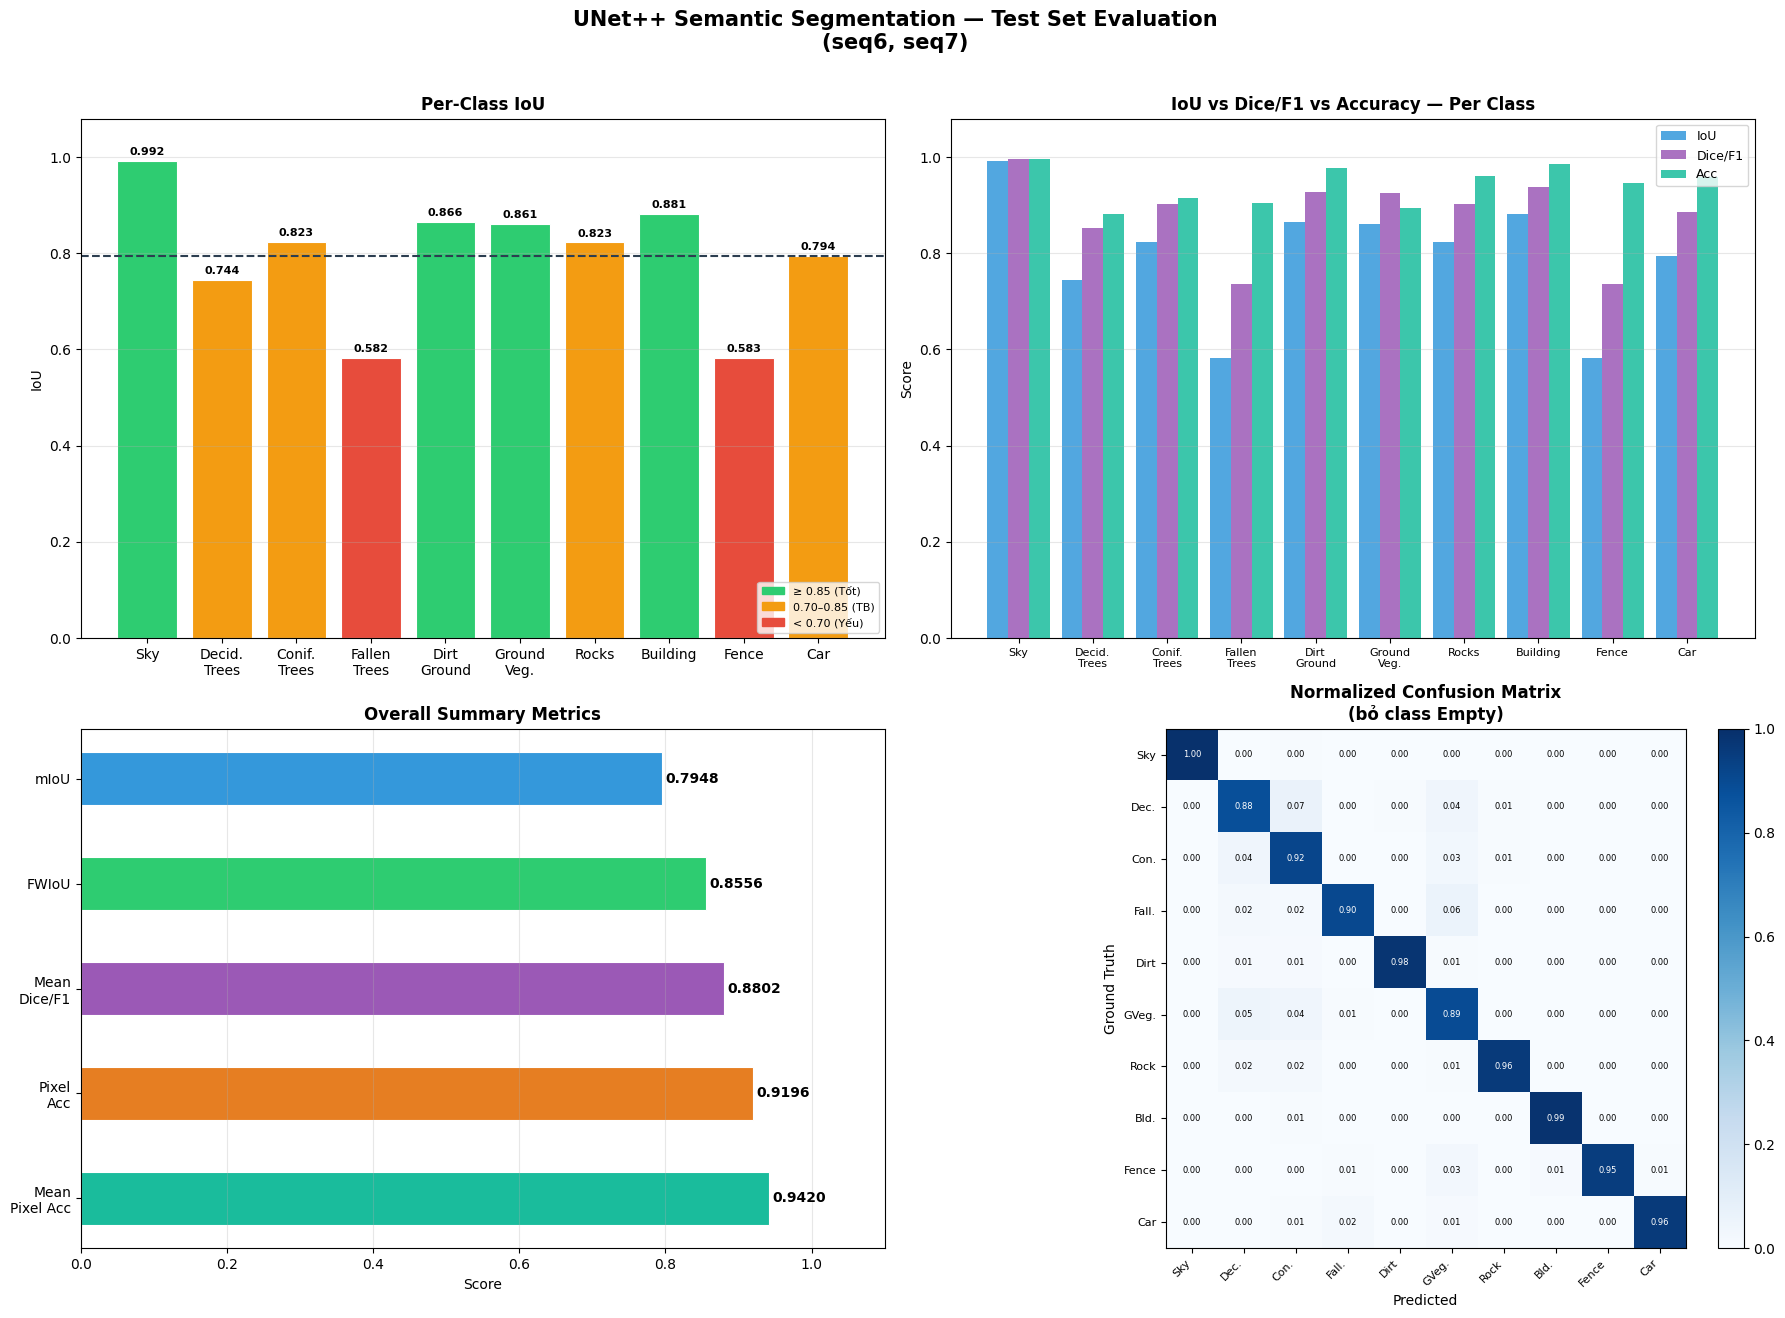

✅ Đã lưu: segmentation_evaluation.png


In [20]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# ── Dữ liệu ──────────────────────────────────────────────
class_names_short = [
    'Sky', 'Decid.\nTrees', 'Conif.\nTrees', 'Fallen\nTrees',
    'Dirt\nGround', 'Ground\nVeg.', 'Rocks', 'Building', 'Fence', 'Car'
]

# Cắt lấy 10 class đầu tiên (bỏ class Empty ở cuối)
iou_vals  = results['iou_per_class'][:10]
dice_vals = results['dice_per_class'][:10]
cm_test_10 = cm_test[:10, :10] # Cắt confusion matrix về 10x10

# Khắc phục RuntimeWarning: Chỉ thực hiện phép chia ở những class có dữ liệu
row_sums = cm_test_10.sum(axis=1)
acc_vals = np.zeros_like(row_sums, dtype=float)
valid_mask = row_sums > 0
acc_vals[valid_mask] = np.diag(cm_test_10)[valid_mask] / row_sums[valid_mask]

summary_names  = ['mIoU', 'FWIoU', 'Mean\nDice/F1', 'Pixel\nAcc', 'Mean\nPixel Acc']
summary_vals   = [results['miou'], results['fwiou'],
                  results['mean_dice'], results['pixel_acc'], results['mean_pixel_acc']]

# ── Màu sắc theo IoU ─────────────────────────────────────
def iou_color(v):
    if v >= 0.85: return '#2ecc71'   # xanh lá = tốt
    if v >= 0.70: return '#f39c12'   # cam = trung bình
    return '#e74c3c'                 # đỏ = yếu

colors = [iou_color(v) for v in iou_vals]

fig, axes = plt.subplots(2, 2, figsize=(18, 13))
fig.suptitle('UNet++ Semantic Segmentation — Test Set Evaluation\n(seq6, seq7)',
             fontsize=15, fontweight='bold', y=1.01)

# ── 1. Per-class IoU ──────────────────────────────────────
ax = axes[0, 0]
bars = ax.bar(class_names_short, iou_vals, color=colors, edgecolor='white', linewidth=0.8)
ax.axhline(results['miou'], color='#2c3e50', linestyle='--', linewidth=1.5,
           label=f"mIoU = {results['miou']:.4f}")
for bar, v in zip(bars, iou_vals):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.008, f'{v:.3f}',
            ha='center', va='bottom', fontsize=8, fontweight='bold')
ax.set_ylim(0, 1.08)
ax.set_title('Per-Class IoU', fontweight='bold')
ax.set_ylabel('IoU')
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)
patches = [mpatches.Patch(color='#2ecc71', label='≥ 0.85 (Tốt)'),
           mpatches.Patch(color='#f39c12', label='0.70–0.85 (TB)'),
           mpatches.Patch(color='#e74c3c', label='< 0.70 (Yếu)')]
ax.legend(handles=patches, fontsize=8, loc='lower right')

# ── 2. IoU vs Dice vs Acc (grouped bar) ───────────────────
ax = axes[0, 1]
x = np.arange(len(class_names_short))
w = 0.28
ax.bar(x - w, iou_vals,  w, label='IoU',     color='#3498db', alpha=0.85)
ax.bar(x,     dice_vals, w, label='Dice/F1', color='#9b59b6', alpha=0.85)
ax.bar(x + w, acc_vals,  w, label='Acc',     color='#1abc9c', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(class_names_short, fontsize=8)
ax.set_ylim(0, 1.08)
ax.set_title('IoU vs Dice/F1 vs Accuracy — Per Class', fontweight='bold')
ax.set_ylabel('Score')
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)

# ── 3. Summary metrics (horizontal bar) ───────────────────
ax = axes[1, 0]
bar_colors = ['#3498db','#2ecc71','#9b59b6','#e67e22','#1abc9c']
hbars = ax.barh(summary_names, summary_vals, color=bar_colors,
                edgecolor='white', linewidth=0.8, height=0.5)
for bar, v in zip(hbars, summary_vals):
    ax.text(v + 0.005, bar.get_y() + bar.get_height()/2,
            f'{v:.4f}', va='center', fontsize=10, fontweight='bold')
ax.set_xlim(0, 1.1)
ax.set_title('Overall Summary Metrics', fontweight='bold')
ax.set_xlabel('Score')
ax.grid(axis='x', alpha=0.3)
ax.invert_yaxis()

# ── 4. Confusion matrix (normalized) ──────────────────────
ax = axes[1, 1]
# Sử dụng cm_test_10 đã cắt ở trên
cm_norm = cm_test_10.astype(float)
row_sum = cm_norm.sum(1, keepdims=True)
cm_norm = np.where(row_sum > 0, cm_norm / row_sum, 0.0)

short_labels = ['Sky','Dec.','Con.','Fall.','Dirt','GVeg.','Rock','Bld.','Fence','Car']
im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(10)); ax.set_xticklabels(short_labels, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(10)); ax.set_yticklabels(short_labels, fontsize=8)
for i in range(10):
    for j in range(10):
        v = cm_norm[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center',
                fontsize=6, color='white' if v > 0.5 else 'black')
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_title('Normalized Confusion Matrix\n(bỏ class Empty)', fontweight='bold')
ax.set_xlabel('Predicted'); ax.set_ylabel('Ground Truth')

plt.tight_layout()
plt.savefig('segmentation_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Đã lưu: segmentation_evaluation.png")

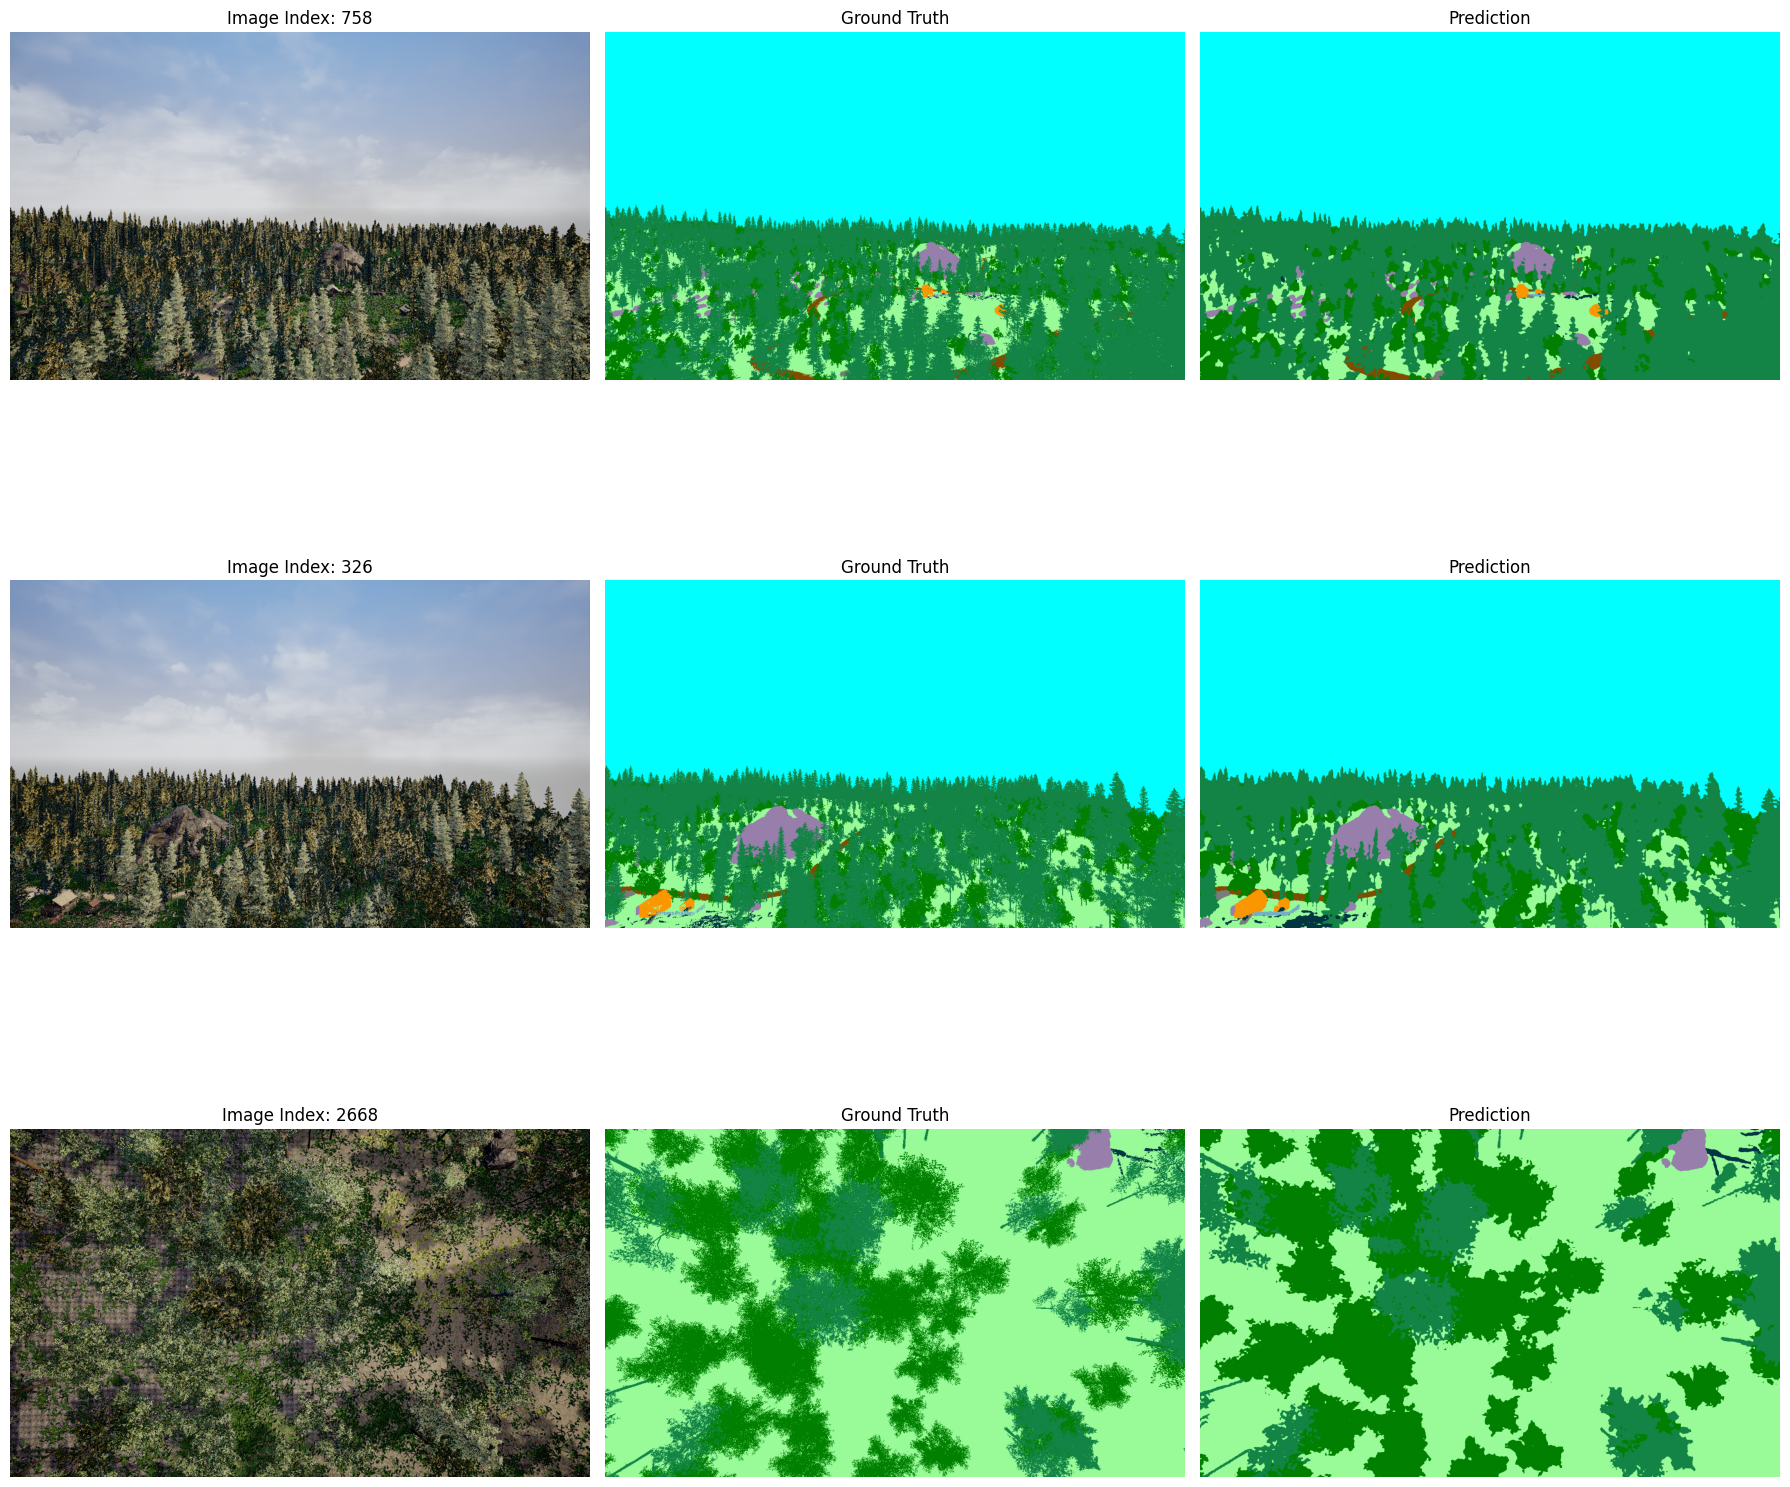

In [22]:
def visualize_predictions(dataset, model, num_samples=3):
    model.eval()
    indices = np.random.choice(len(dataset), num_samples, replace=False)
    
    plt.figure(figsize=(18, 6 * num_samples))
    
    for i, idx in enumerate(indices):
        img_tensor, mask_id = dataset[idx]
        
        # Inference
        with torch.no_grad():
            input_tensor = img_tensor.unsqueeze(0).to(DEVICE)
            out = model(input_tensor)
            pred_id = out.argmax(1).squeeze(0).cpu().numpy()
            
        # Chuyển đổi về RGB để hiển thị
        img_show = img_tensor.permute(1, 2, 0).numpy()
        # Un-normalize ảnh để hiển thị đúng màu
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        img_show = std * img_show + mean
        img_show = np.clip(img_show, 0, 1)
        
        gt_rgb = class_id_to_rgb_fast(mask_id.numpy())
        pred_rgb = class_id_to_rgb_fast(pred_id)
        
        # Vẽ đồ thị
        plt.subplot(num_samples, 3, i*3 + 1)
        plt.imshow(img_show)
        plt.title(f"Image Index: {idx}")
        plt.axis('off')
        
        plt.subplot(num_samples, 3, i*3 + 2)
        plt.imshow(gt_rgb)
        plt.title("Ground Truth")
        plt.axis('off')
        
        plt.subplot(num_samples, 3, i*3 + 3)
        plt.imshow(pred_rgb)
        plt.title("Prediction")
        plt.axis('off')
        
    plt.tight_layout()
    plt.show()

# Chạy thử hiển thị 3 mẫu ngẫu nhiên từ tập Test
visualize_predictions(test_ds, model, num_samples=3)


🔍 PHÂN TÍCH LỖI CÁC OBJECT NHỎ

  [3] Fallen_trees
    GT pixels   : 26,096,401
    IoU         : 0.5823
    Recall      : 0.9043  (bỏ sót 9.6% GT pixels)
    Precision   : 0.6206
    Nhầm thành  :
      → Ground_vegetation     : 1,574,813 px (6.0%)
      → Deciduous_trees       :  409,657 px (1.6%)
      → Coniferous_trees      :  407,226 px (1.6%)

  [8] Fence
    GT pixels   :    418,433
    IoU         : 0.5830
    Recall      : 0.9463  (bỏ sót 5.4% GT pixels)
    Precision   : 0.6030
    Nhầm thành  :
      → Ground_vegetation     :   11,074 px (2.6%)
      → Building              :    3,922 px (0.9%)
      → Fallen_trees          :    3,232 px (0.8%)

  [9] Car
    GT pixels   :  1,915,966
    IoU         : 0.7940
    Recall      : 0.9586  (bỏ sót 4.1% GT pixels)
    Precision   : 0.8222
    Nhầm thành  :
      → Fallen_trees          :   30,168 px (1.6%)
      → Ground_vegetation     :   20,676 px (1.1%)
      → Coniferous_trees      :   12,865 px (0.7%)

  [7] Building
    GT 

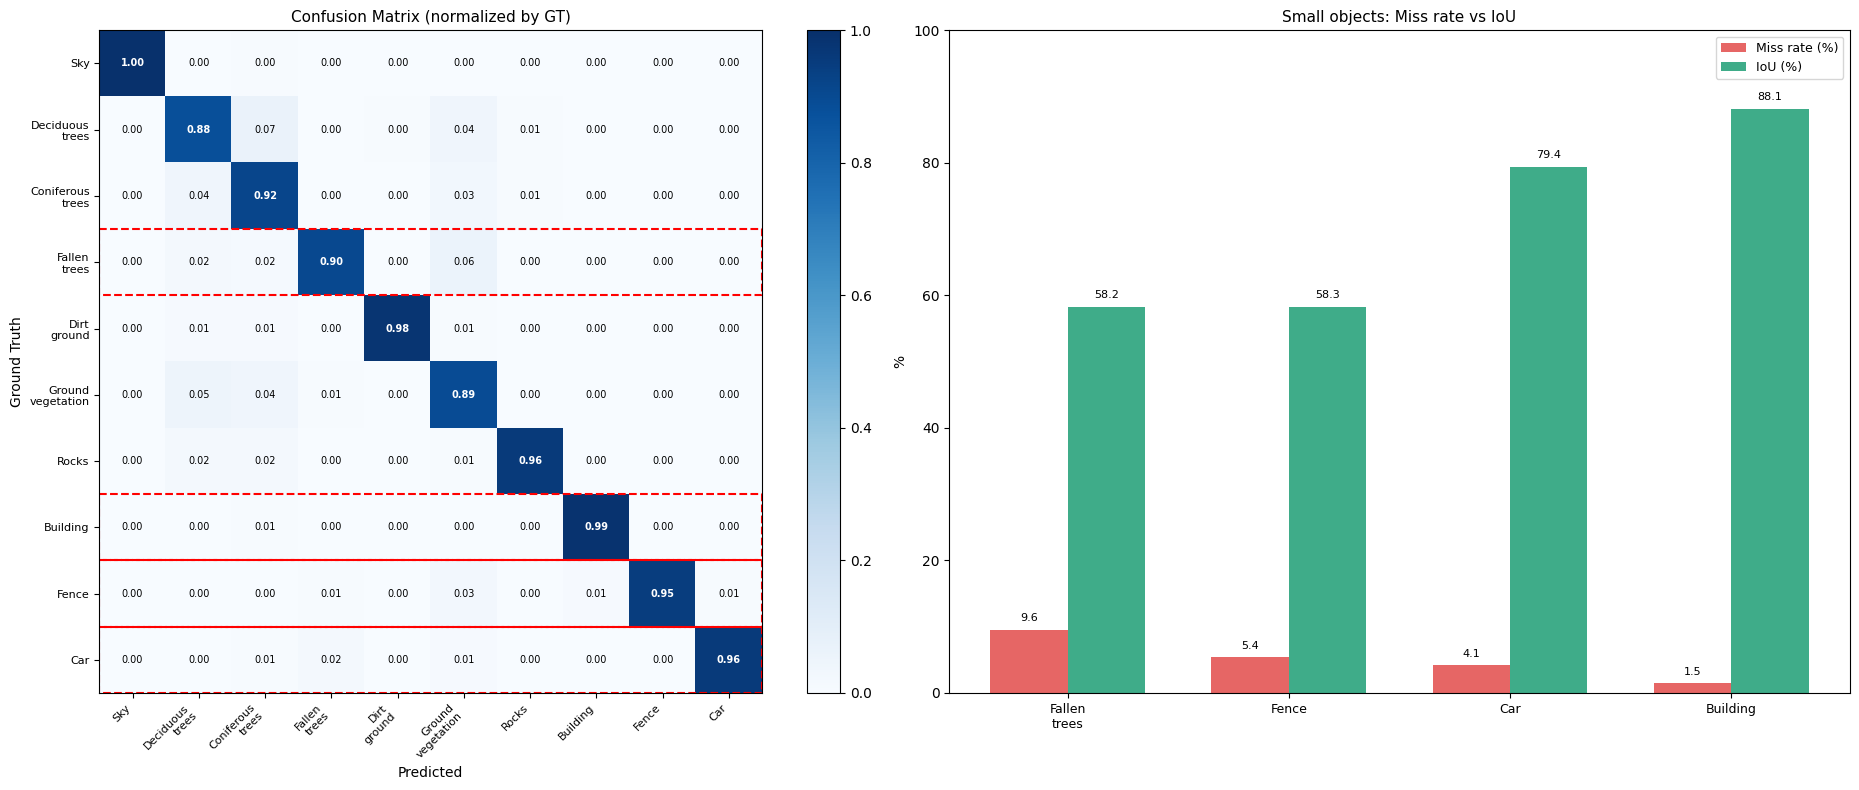

In [23]:
# Phân tích: model thường bị lỗi gì với các object nhỏ?
# Cụ thể: Fallen_trees (3), Fence (8), Car (9), Building (7)
# Các loại lỗi:
#   - Missed: GT có object nhỏ nhưng model bỏ sót hoàn toàn
#   - Confused: model nhầm object nhỏ thành class nào khác
#   - False positive: model predict có object nhỏ ở chỗ không có
SMALL_CLASSES = {
    3: 'Fallen_trees',
    8: 'Fence',
    9: 'Car',
    7: 'Building'
}


def analyze_small_object_errors(cm, class_names, small_class_ids, save_dir=None):
    """
    Phân tích lỗi chi tiết cho các class nhỏ/hiếm.
    In ra:
      1. Recall (Missed detection rate)
      2. Precision (False positive rate)  
      3. Top-3 class bị nhầm nhiều nhất
      4. Heatmap confusion matrix
    """
    n = len(class_names) - 1  # bỏ Empty

    inter     = np.diag(cm)
    row_sum   = cm.sum(axis=1)  # GT pixels per class
    col_sum   = cm.sum(axis=0)  # Predicted pixels per class

    print("\n" + "="*70)
    print("🔍 PHÂN TÍCH LỖI CÁC OBJECT NHỎ")
    print("="*70)

    error_summary = {}
    for cid in small_class_ids:
        name       = class_names[cid]
        tp         = cm[cid, cid]
        fn         = row_sum[cid] - tp          # GT có, predict sai
        fp         = col_sum[cid] - tp          # Predict có, GT không có
        total_gt   = row_sum[cid]
        recall     = tp / total_gt if total_gt > 0 else 0
        precision  = tp / (tp + fp) if (tp + fp) > 0 else 0
        iou        = tp / (tp + fp + fn) if (tp + fp + fn) > 0 else 0
        miss_rate  = fn / total_gt if total_gt > 0 else 0  # tỷ lệ bỏ sót

        # Top 3 class bị nhầm (bỏ qua chính class đó và Empty)
        confusion_row = cm[cid].copy()
        confusion_row[cid] = 0              # bỏ TP
        confusion_row[-1]  = 0              # bỏ Empty
        top3_confused = np.argsort(confusion_row)[::-1][:3]

        print(f"\n  [{cid}] {name}")
        print(f"    GT pixels   : {total_gt:>10,}")
        print(f"    IoU         : {iou:.4f}")
        print(f"    Recall      : {recall:.4f}  (bỏ sót {miss_rate*100:.1f}% GT pixels)")
        print(f"    Precision   : {precision:.4f}")
        print(f"    Nhầm thành  :")
        for j in top3_confused:
            n_confused = confusion_row[j]
            if n_confused > 0:
                pct = n_confused / total_gt * 100 if total_gt > 0 else 0
                print(f"      → {class_names[j]:<22}: {n_confused:>8,} px ({pct:.1f}%)")

        error_summary[name] = {
            'iou': iou, 'recall': recall, 'precision': precision,
            'miss_rate': miss_rate, 'total_gt_px': int(total_gt),
            'top_confusion': [(class_names[j], int(confusion_row[j]))
                              for j in top3_confused if confusion_row[j] > 0]
        }

    # ── CONFUSION MATRIX HEATMAP (normalized) ──────────────
    fig, axes = plt.subplots(1, 2, figsize=(20, 8))

    # Plot 1: Full confusion matrix
    cm_norm = cm[:n, :n].astype(float)
    row_s   = cm_norm.sum(axis=1, keepdims=True)
    cm_norm = np.where(row_s > 0, cm_norm / row_s, 0)

    im = axes[0].imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
    axes[0].set_xticks(range(n))
    axes[0].set_yticks(range(n))
    axes[0].set_xticklabels([c.replace('_', '\n') for c in class_names[:n]],
                             fontsize=8, rotation=45, ha='right')
    axes[0].set_yticklabels([c.replace('_', '\n') for c in class_names[:n]], fontsize=8)
    axes[0].set_xlabel('Predicted', fontsize=10)
    axes[0].set_ylabel('Ground Truth', fontsize=10)
    axes[0].set_title('Confusion Matrix (normalized by GT)', fontsize=11)
    plt.colorbar(im, ax=axes[0], fraction=0.046)

    for i in range(n):
        for j in range(n):
            val = cm_norm[i, j]
            color = 'white' if val > 0.5 else 'black'
            weight = 'bold' if i == j else 'normal'
            axes[0].text(j, i, f'{val:.2f}', ha='center', va='center',
                         fontsize=7, color=color, fontweight=weight)

    # Highlight các small classes bằng khung đỏ
    for cid in small_class_ids:
        if cid < n:
            axes[0].add_patch(plt.Rectangle(
                (-0.5, cid - 0.5), n, 1,
                fill=False, edgecolor='red', linewidth=1.5, linestyle='--'))

    # Plot 2: Miss rate của small objects
    small_ids_valid = [c for c in small_class_ids if c < n]
    names_s    = [class_names[c] for c in small_ids_valid]
    miss_rates = [error_summary[class_names[c]]['miss_rate'] * 100
                  for c in small_ids_valid]
    ious_s     = [error_summary[class_names[c]]['iou'] * 100
                  for c in small_ids_valid]

    x = np.arange(len(names_s))
    w = 0.35
    bars1 = axes[1].bar(x - w/2, miss_rates, w, label='Miss rate (%)',
                        color='#E24B4A', alpha=0.85)
    bars2 = axes[1].bar(x + w/2, ious_s,    w, label='IoU (%)',
                        color='#1D9E75', alpha=0.85)

    axes[1].set_xticks(x)
    axes[1].set_xticklabels([n.replace('_', '\n') for n in names_s], fontsize=9)
    axes[1].set_ylabel('%', fontsize=10)
    axes[1].set_title('Small objects: Miss rate vs IoU', fontsize=11)
    axes[1].legend(fontsize=9)
    axes[1].set_ylim(0, 100)

    for bar in bars1:
        h = bar.get_height()
        if h > 0:
            axes[1].text(bar.get_x() + bar.get_width()/2, h + 1,
                         f'{h:.1f}', ha='center', va='bottom', fontsize=8)
    for bar in bars2:
        h = bar.get_height()
        if h > 0:
            axes[1].text(bar.get_x() + bar.get_width()/2, h + 1,
                         f'{h:.1f}', ha='center', va='bottom', fontsize=8)

    plt.tight_layout()
    if save_dir:
        path = Path(save_dir) / 'small_object_error_analysis.png'
        plt.savefig(path, dpi=150, bbox_inches='tight')
        print(f"\n💾 Saved: {path}")
    plt.show()

    return error_summary

# Chạy phân tích
small_class_ids = list(SMALL_CLASSES.keys())  # [3, 7, 8, 9]
error_summary = analyze_small_object_errors(
    cm_test, CLASS_NAMES, small_class_ids,
    save_dir=OUTPUT_DIR
)